# 01 — EDA: human vs ai vs fusion

Class balance by language/domain, text lengths, examples, what makes **fusion** different, and how texts are grouped (needed for a leak-free validation split).

**Run on Kaggle**
1. *Create → New Notebook → File → Import Notebook* → upload this file.
2. *Settings*: Accelerator **None (CPU)**.
3. *Add Input*: competition **ai-generated-text-detection-hw3-ucu-ai-2026**.
4. *Save Version → Save & Run All (Commit)*. **ETA: ~10 min.**

**Copy back into the repo** (from the version's *Output* tab):
- this notebook with outputs → `notebooks/01_eda.ipynb`
- `eda_*.png` → `reports/figures/`


In [1]:
import os, glob, re, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SMOKE = bool(os.environ.get('SMOKE'))  # tiny local dry-run of the whole notebook; never set on Kaggle
OUT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUT.mkdir(exist_ok=True)
SEED, LABELS = 42, ['human', 'ai', 'fusion']
L2I = {l: i for i, l in enumerate(LABELS)}

def find(name):
    """Locate an input file in attached Kaggle inputs (or ../data locally)."""
    for root in ['/kaggle/input', '../data', str(OUT)]:
        hits = sorted(glob.glob(f'{root}/**/{name}', recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{name} not found: attach the inputs listed at the top of this notebook')

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")  # the competition metric

def report(y_true, y_pred, title):
    """Per-class metrics + normalized confusion matrix (labels are class indices)."""
    print(f'{title}: macro-F1 = {macro_f1(y_true, y_pred):.4f}')
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=4))
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues', values_format='.3f')
    plt.title(title); plt.grid(False)
    plt.savefig(OUT / f"cm_{re.sub(r'[^a-z0-9]+', '_', title.lower())}.png", dpi=120, bbox_inches='tight'); plt.show()

def f1_by(df, pred_col, by):
    return df.groupby(by).apply(lambda d: macro_f1(d.y, d[pred_col])).round(4).rename('macro_f1').to_frame().join(df[by].value_counts().rename('n'))

train = pd.read_csv(find('train.csv'))
test = pd.read_csv(find('test.csv'))
sub = pd.read_csv(find('sample_submission.csv'))
if SMOKE:
    test = test.head(300); sub = sub[sub.id.isin(test.id)]
train['y'] = train.label.map(L2I)
print(train.shape, test.shape)

(272352, 6) (25000, 4)


In [2]:
print('nulls:', train.isna().sum().to_dict())
print('duplicate texts in train:', train.text.duplicated().sum(), '| test texts also in train:', test.text.isin(set(train.text)).sum())

nulls: {'id': 0, 'text': 0, 'lang': 0, 'domain': 0, 'label': 0, 'y': 0}
duplicate texts in train: 0 | test texts also in train: 0


## 1. Class balance — overall, by language, by domain

In [3]:
print(train.label.value_counts().to_frame('n').assign(share=lambda d: (d.n / d.n.sum()).round(3)))
pd.crosstab([train.lang, train.domain], train.label, margins=True)[LABELS + ['All']]

             n  share
label                
ai      121940  0.448
fusion   83682  0.307
human    66730  0.245


label                         human      ai  fusion     All
lang  domain                                               
de-DE bundestag               14479   19977   17887   52343
      gutenberg                  31     360      37     428
en-EN arxiv_papers              407   12050    1833   14290
      blog_authorship_corpus  12466   15684   12397   40547
      cnn_news                13395   19488   11402   44285
      euro_court_cases         6277   11141   10160   27578
      gutenberg                 216    6359     341    6916
      house_of_commons         6953   15298    9608   31859
      student_essays          12506   21583   20017   54106
All                           66730  121940   83682  272352

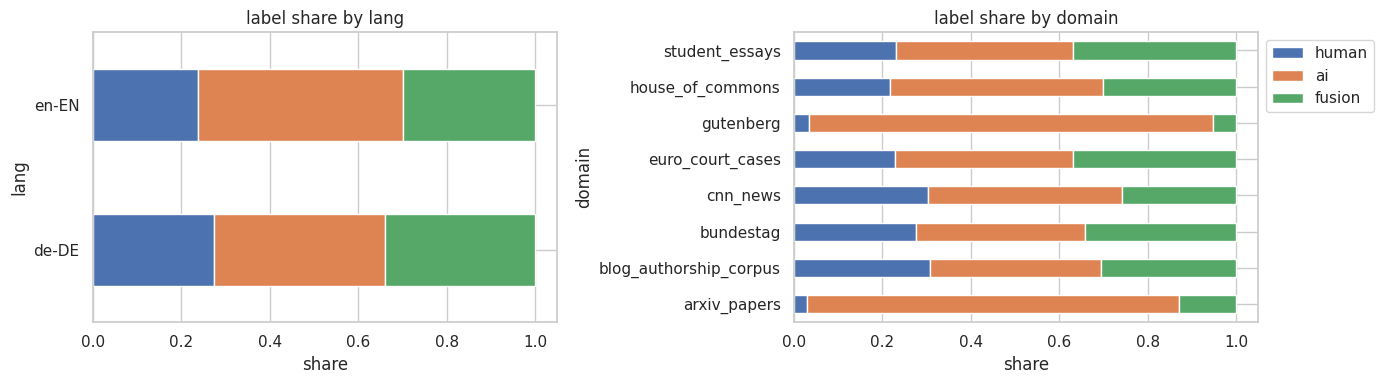

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['lang', 'domain']):
    pd.crosstab(train[col], train.label, normalize='index')[LABELS].plot.barh(stacked=True, ax=ax, legend=ax is axes[1])
    ax.set_title(f'label share by {col}'); ax.set_xlabel('share')
axes[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.savefig(OUT / 'eda_balance.png', dpi=120); plt.show()

Train vs test language/domain mix (the validation split should mimic test).

In [5]:
pd.concat({'train': train.groupby(['lang', 'domain']).size() / len(train),
           'test': test.groupby(['lang', 'domain']).size() / len(test)}, axis=1).round(3)

train   test
lang  domain                              
de-DE bundestag               0.192  0.143
      gutenberg               0.002  0.004
en-EN arxiv_papers            0.052  0.067
      blog_authorship_corpus  0.149  0.178
      cnn_news                0.163  0.197
      euro_court_cases        0.101  0.064
      gutenberg               0.025  0.070
      house_of_commons        0.117  0.118
      student_essays          0.199  0.159

## 2. Text lengths

In [6]:
for df in (train, test):
    df['n_words'] = df.text.str.split().str.len()
train.groupby('label').n_words.describe().loc[LABELS].round(0)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
human,66730.0,578.0,473.0,20.0,262.0,481.0,740.0,2998.0
ai,121940.0,493.0,294.0,20.0,287.0,465.0,657.0,2996.0
fusion,83682.0,585.0,531.0,20.0,263.0,445.0,695.0,3000.0


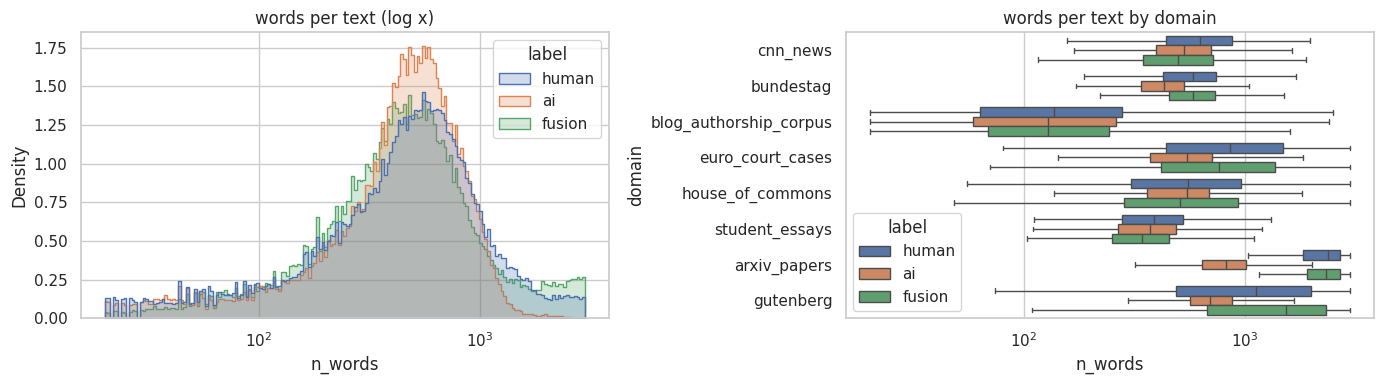

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train, x='n_words', hue='label', hue_order=LABELS, log_scale=True, element='step', stat='density', common_norm=False, ax=axes[0])
axes[0].set_title('words per text (log x)')
sns.boxplot(train, y='domain', x='n_words', hue='label', hue_order=LABELS, log_scale=True, showfliers=False, ax=axes[1])
axes[1].set_title('words per text by domain')
plt.tight_layout(); plt.savefig(OUT / 'eda_lengths.png', dpi=120); plt.show()

In [8]:
# share of texts a 512-token encoder would truncate (rough: ~1.4 subword tokens per word)
too_long = train.n_words * 1.4 > 510
print('approx > 512 tokens:', round(too_long.mean(), 3))
too_long.groupby(train.label).mean().round(3)

approx > 512 tokens: 0.638


label
ai        0.656
fusion    0.612
human     0.639
Name: n_words, dtype: float64

## 3. Examples of each class

In [9]:
for _, r in train.groupby(['lang', 'label']).sample(1, random_state=SEED).iterrows():
    print(f'[{r.lang} | {r.domain} | {r.label} | {r.n_words} words]\n{r.text[:400]}...\n')

[de-DE | bundestag | ai | 277 words]
"Sehr geehrte Damen und Herren, liebe Kolleginnen und Kollegen, heute möchte ich mich zum Gesetzentwurf zur Vereinfachung des Meldewesens im Gastgewerbe äußern. Wie wir alle wissen, ist unsere deutsche Gastronomie ein essenzieller Teil unserer Wirtschaft und eines unverzichtbaren Aushängeschilds unseres Landes. Es leistet einen wichtigen Beitrag zu unserem Wohlstand und schafft unzählige Arbeitspl...

[de-DE | bundestag | fusion | 672 words]
Herr Präsident! Liebe Kolleginnen und Kollegen! Lassen Sie mich zu Beginn etwas zu dem Vortrag der Kollegin Vogler von der Fraktion Die Linke sagen. Frau Vogler, Sie haben in Ihrer Rede die Situation von Soldatenfrauen, von den Partnern unserer Soldaten mit großer Empathie beschrieben. Ich sage Ihnen ganz offen: Diese Empathie würde ich mir wünschen, wenn wir beispielsweise in den Ausschüssen oder...

[de-DE | bundestag | human | 615 words]
– Der war gut, Herr Mindrup. – Herr Präsident! Meine Damen und Herren! L

## 4. Groups: a human text and its ai/fusion versions

The task says a human text and its rewrites stay on the same side of the train/test split, but `train.csv` has no group id. If a random split puts a human text in train and its fusion version in val, validation is optimistic. We link texts that share their first or last 10 words (same function as in `02_baseline`).

In [10]:
from scipy import sparse
from scipy.sparse.csgraph import connected_components

def make_groups(texts):
    """Link texts that share their first or last 10 words (a human text and its fusion/ai rewrite) into groups."""
    w = texts.str.lower().str.split()
    keys = pd.concat([w.str[:10].str.join(' ').radd('h:'), w.str[-10:].str.join(' ').radd('t:')], ignore_index=True)
    rows = np.tile(np.arange(len(texts)), 2)
    codes, uniq = pd.factorize(keys)
    keep = np.bincount(codes)[codes] <= 20  # very common openings/closings are boilerplate, not rewrites
    n = len(texts)
    g = sparse.coo_matrix((np.ones(keep.sum()), (rows[keep], n + codes[keep])), shape=(n + len(uniq),) * 2)
    return connected_components(g, directed=False)[1][:n]

In [11]:
train['group'] = make_groups(train.text)
sizes = train.group.map(train.group.value_counts())
print('rows in multi-text groups:', round((sizes > 1).mean(), 3), '| largest group:', sizes.max())
print('group size counts:', train.group.value_counts().value_counts().sort_index().head(8).to_dict())
train[sizes > 1].groupby('group').label.agg(lambda s: '+'.join(sorted(s))).value_counts().head(10)

rows in multi-text groups: 0.495 | largest group: 453
group size counts: {1: 137642, 2: 31703, 3: 13818, 4: 1709, 5: 771, 6: 625, 7: 253, 8: 206}


label
fusion+human                        24459
fusion+fusion+human                 12557
fusion+fusion                        4621
ai+ai                                2490
fusion+fusion+fusion+human            765
ai+ai+ai                              680
fusion+fusion+human+human             462
fusion+fusion+fusion+human+human      344
fusion+fusion+fusion                  342
ai+ai+ai+ai                           316
Name: count, dtype: int64

## 5. What makes fusion different? Stylometry

Cheap per-text features on a fixed stratified 30k sample; medians per class and language.

In [12]:
def stylo(t):
    """Cheap stylometric features of one text."""
    w = t.split()
    sents = [s for s in re.split(r'[.!?]+\s', t) if s.strip()]
    return {
        'n_words': len(w),
        'avg_word_len': np.mean([len(x) for x in w]),
        'avg_sent_words': len(w) / max(len(sents), 1),
        'type_token': len({x.lower() for x in w[:200]}) / max(len(w[:200]), 1),  # first 200 words: TTR depends on length
        'punct_per_word': sum(c in ',;:()"-–—' for c in t) / len(w),
        'upper_ratio': sum(c.isupper() for c in t) / len(t),
        'newlines_per_100w': t.count('\n') * 100 / len(w),
        'digits_ratio': sum(c.isdigit() for c in t) / len(t),
    }

In [13]:
sample = train.groupby('label').sample(200 if SMOKE else 10_000, random_state=SEED)
S = pd.concat([sample[['lang', 'domain', 'label']], pd.DataFrame([stylo(t) for t in sample.text], index=sample.index)], axis=1)
S.groupby(['lang', 'label']).median(numeric_only=True).round(3)

n_words  avg_word_len  avg_sent_words  type_token  \
lang  label                                                       
de-DE ai        425.0         6.266          16.655       0.715   
      fusion    584.0         6.004          15.739       0.710   
      human     588.0         5.895          15.578       0.710   
en-EN ai        478.0         5.451          18.425       0.700   
      fusion    389.0         4.953          17.935       0.650   
      human     445.0         4.744          18.273       0.630   

              punct_per_word  upper_ratio  newlines_per_100w  digits_ratio  
lang  label                                                                 
de-DE ai               0.090        0.045                0.0         0.000  
      fusion           0.095        0.045                0.0         0.002  
      human            0.099        0.046                0.0         0.002  
en-EN ai               0.081        0.019                0.0         0.000  
      fusion           0.059        0.022                0.0         0.003  
      human            0.060        0.026                0.0         0.004

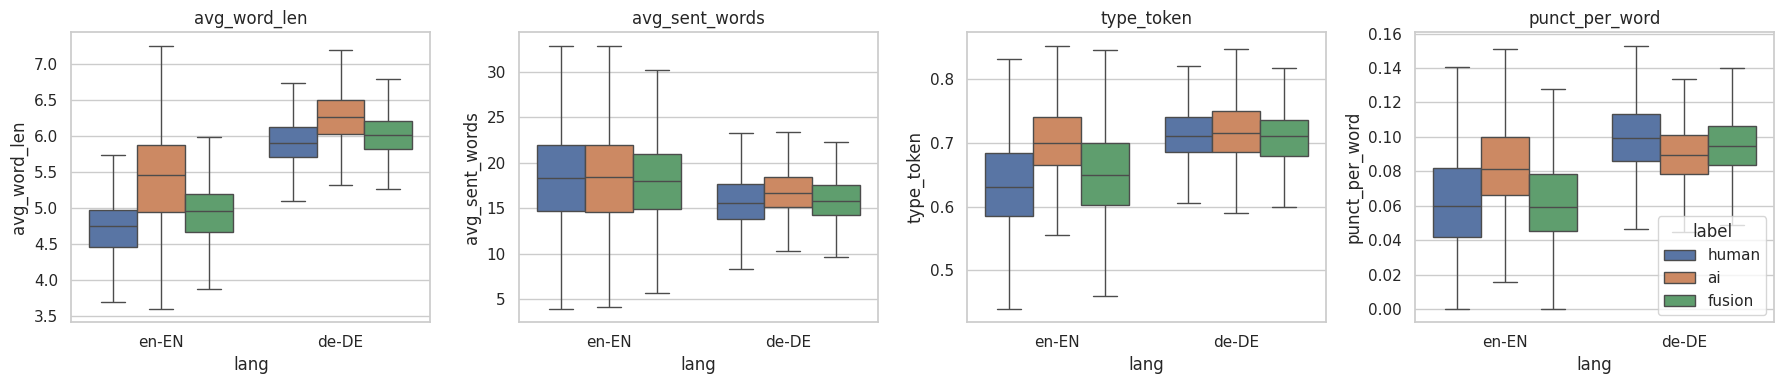

In [14]:
feats = ['avg_word_len', 'avg_sent_words', 'type_token', 'punct_per_word']
fig, axes = plt.subplots(1, len(feats), figsize=(18, 4))
for ax, f in zip(axes, feats):
    sns.boxplot(S, x='lang', y=f, hue='label', hue_order=LABELS, showfliers=False, ax=ax, legend=ax is axes[-1])
    ax.set_title(f)
plt.tight_layout(); plt.savefig(OUT / 'eda_stylometry.png', dpi=120); plt.show()

Matched pairs: inside groups holding a human text and its rewrite, how much of the text survives? (word-level similarity of the first 300 words)

In [15]:
from difflib import SequenceMatcher
multi = train[sizes > 1]
rows = []
for other in ['fusion', 'ai']:
    pairs = multi[multi.label.isin(['human', other])].groupby('group').filter(lambda d: d.label.nunique() == 2)
    for _, d in list(pairs.groupby('group'))[:200]:
        h, o = d[d.label == 'human'].text.iloc[0].split()[:300], d[d.label == other].text.iloc[0].split()[:300]
        rows.append({'human_vs': other, 'similarity': SequenceMatcher(None, h, o, autojunk=False).ratio()})
pd.DataFrame(rows).groupby('human_vs').similarity.describe().round(2) if rows else 'no matched pairs found'


,count,mean,std,min,25%,50%,75%,max
human_vs,,,,,,,,
ai,151.0,0.12,0.15,0.02,0.05,0.08,0.11,0.94
fusion,200.0,0.68,0.30,0.03,0.48,0.72,0.98,1.00


## 6. Takeaways

- **Class balance.** ai 44.8%, fusion 30.7%, human 24.5%. The imbalance is mild, but macro-F1 weighs the smallest class (human) equally, so class weights or thresholds are worth testing (04, E3).
- **Domain is a strong prior.** arxiv papers (84% ai) and English gutenberg (92% ai) are almost all ai, while the other domains are mixed. The validation split is stratified by label × language × domain, and the stacker gets `lang`/`domain` as features. Test has a different mix from train: more gutenberg (7.0% vs 2.5%), news and blogs, less bundestag and court cases. Per-domain F1 therefore matters, and the leaderboard can differ from val.
- **Length.** Medians are 445–481 words for all classes. Human and fusion have long tails (std ≈ 500 words vs 294 for ai). About 64% of texts exceed 512 tokens (69% with the real mDeBERTa tokenizer, see 03), so long-text handling is needed: head / head+tail / chunks (03).
- **What makes fusion different.** Fusion keeps most of the original human text: a median of 72% of the first 300 words survive, against 8% for an ai version of the same text. Its stylometry sits between human and ai but much closer to human (EN word length 4.74 / 4.95 / 5.45, type-token ratio 0.63 / 0.65 / 0.70 for human / fusion / ai). Global features therefore blur fusion with human, and local (window- or segment-level) signals are needed. This motivates the chunk window statistics (03b) and the segment features (04).
- **Groups.** 49.5% of rows belong to multi-text groups, mostly a human text with its fusion version(s). A random split would put a human text in train and its rewrite in val and inflate the scores, so 02 uses a **group-aware split**.
- No missing values, no duplicate texts, and no test text appears in train.